# Year-on-Year Returns vs Value at Risk

Is risk compensated? This notebook compares each index's **calendar-year return** with its **GJR-GARCH-t one-day VaR** and asks two questions:

1. **Contemporaneous:** are years with high average VaR also years with low (or high) returns?
2. **Predictive:** does the VaR at the *start* of a year tell us anything about the return over the *following* year?

It also looks at a daily rolling version: the trailing 252-day return against the VaR on each day.

**Inputs.** Cached prices from `data/<index>_daily.csv`, written by the three Stage 1 notebooks (`nifty.ipynb`, `sp500.ipynb`, `eurostoxx50.ipynb`). Original source: Yahoo Finance via `yfinance`.

**VaR series.** The Stage 1 notebooks only export VaR for the 2018–2025 test window. To get enough yearly observations, this notebook re-estimates the same GJR-GARCH(1,1,1)-t model on the same training window (to 2017) and runs it over the **whole** history with fixed parameters. Years before 2018 are therefore **in-sample**: the parameters were fitted on them. They are flagged separately throughout, and the test-window values are checked against the Stage 1 exports.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from scipy import stats

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:.3f}".format)

SPLIT = "2018-01-01"
LEVEL = 0.99            # main VaR level analysed; 95% is reported alongside
INDICES = {
    "NIFTY 50":      "nifty50",
    "S&P 500":       "sp500",
    "Euro Stoxx 50": "eurostoxx50",
}
COLORS = {"NIFTY 50": "C1", "S&P 500": "C0", "Euro Stoxx 50": "C2"}
DATA = Path("data")

## 1. Daily VaR for the full history

The model is GJR-GARCH(1,1,1) with a constant mean and Student-t innovations, fitted with `last_obs=SPLIT` as in Stage 1. `forecast(start=…)` then gives the one-step-ahead mean and volatility for every day, using only information up to the day before.

$$\text{VaR}^{c}_{t+1} = -\left(\hat\mu + \hat\sigma_{t+1|t}\, q_{1-c}\right)$$

In [2]:
def load_prices(slug):
    p = pd.read_csv(DATA / f"{slug}_daily.csv", index_col="Date", parse_dates=True)["Close"]
    return p.dropna()[lambda s: ~s.index.duplicated()]

def full_history_var(prices):
    r = (100 * np.log(prices).diff()).dropna()
    model = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
    res = model.fit(last_obs=SPLIT, disp="off")
    fc = res.forecast(horizon=1, start=r.index[0], reindex=False)
    mu, sigma = fc.mean["h.1"].shift(1), np.sqrt(fc.variance["h.1"]).shift(1)
    nu = res.params[["nu"]].values
    out = pd.DataFrame({"r": r, "mu": mu, "sigma": sigma})
    for c in (0.95, 0.99):
        out[f"VaR_{int(c*100)}"] = -(mu + sigma * model.distribution.ppf(1 - c, nu))
    return out.dropna()

prices, daily = {}, {}
for name, slug in INDICES.items():
    prices[name] = load_prices(slug)
    daily[name] = full_history_var(prices[name])
    # check: test-window VaR matches the Stage 1 export
    stage1 = pd.read_csv(DATA / f"{slug}_garch_forecasts.csv", index_col=0, parse_dates=True)
    diff = (daily[name]["VaR_99"].reindex(stage1.index) - stage1["VaR_99_pct"]).abs().max()
    print(f"{name:14s} {daily[name].index[0].date()} -> {daily[name].index[-1].date()}   "
          f"max |VaR99 - Stage 1| on test window = {diff:.2e}")

NIFTY 50       2007-09-19 -> 2025-12-31   max |VaR99 - Stage 1| on test window = 1.78e-15
S&P 500        1990-01-04 -> 2025-12-31   max |VaR99 - Stage 1| on test window = 1.78e-15
Euro Stoxx 50  2007-04-03 -> 2025-12-30   max |VaR99 - Stage 1| on test window = 1.78e-15


## 2. Calendar-year returns and VaR

For each full calendar year:

* **Return (%)**: simple price return from the last close of the previous year to the last close of the year. These are price-index returns, so dividends are not included.
* **Average VaR (%)**: the mean of the daily one-day VaR forecasts during the year. This is the *contemporaneous* risk measure.
* **Start-of-year VaR (%)**: the VaR forecast for the first trading day of the year. It uses only information available before the year begins, so it is the *predictive* risk measure.
* **Sample**: `train` (in-sample, before 2018) or `test` (2018–2025).

A year is included only if the previous year-end close is available, so the first, partial year of each series is dropped.

In [3]:
def yearly_table(name):
    p, d = prices[name], daily[name]
    year_end = p.groupby(p.index.year).last()
    ret = (100 * year_end.pct_change()).dropna()          # needs previous year-end close
    years = ret.index
    g = d.groupby(d.index.year)
    tbl = pd.DataFrame({
        "return": ret,
        "avg_VaR_99": g["VaR_99"].mean().reindex(years),
        "avg_VaR_95": g["VaR_95"].mean().reindex(years),
        "start_VaR_99": g["VaR_99"].first().reindex(years),
        "start_VaR_95": g["VaR_95"].first().reindex(years),
    })
    tbl["sample"] = np.where(tbl.index >= int(SPLIT[:4]), "test", "train")
    tbl.index.name = "year"
    return tbl.dropna()

yearly = {name: yearly_table(name) for name in INDICES}
for name, t in yearly.items():
    print(f"{name}: {t.index[0]}–{t.index[-1]}  ({len(t)} years, {(t['sample']=='test').sum()} in test window)")

pd.concat(yearly, axis=1).sort_index().loc[:, (slice(None), ["return", "avg_VaR_99", "start_VaR_99"])].round(2)

NIFTY 50: 2008–2025  (18 years, 8 in test window)
S&P 500: 1991–2025  (35 years, 8 in test window)
Euro Stoxx 50: 2008–2025  (18 years, 8 in test window)


NIFTY 50                         S&P 500                          \
       return avg_VaR_99 start_VaR_99  return avg_VaR_99 start_VaR_99   
year                                                                    
1991      NaN        NaN          NaN  26.310      2.080        1.670   
1992      NaN        NaN          NaN   4.460      1.670        1.550   
1993      NaN        NaN          NaN   7.060      1.520        1.300   
1994      NaN        NaN          NaN  -1.540      1.740        1.260   
1995      NaN        NaN          NaN  34.110      1.300        1.530   
1996      NaN        NaN          NaN  20.260      1.860        1.730   
1997      NaN        NaN          NaN  31.010      2.620        2.430   
1998      NaN        NaN          NaN  26.670      2.880        2.540   
1999      NaN        NaN          NaN  19.530      2.710        2.360   
2000      NaN        NaN          NaN -10.140      3.300        1.460   
2001      NaN        NaN          NaN -13.040      3.400        3.890   
2002      NaN        NaN          NaN -23.370      3.810        2.320   
2003      NaN        NaN          NaN  26.380      2.520        3.010   
2004      NaN        NaN          NaN   8.990      1.850        1.260   
2005      NaN        NaN          NaN   3.000      1.770        1.310   
2006      NaN        NaN          NaN  13.620      1.630        1.550   
2007      NaN        NaN          NaN   3.530      2.470        1.330   
2008  -51.790      6.720        3.980 -38.490      5.510        3.020   
2009   75.760      4.560        5.970  23.450      4.000        6.470   
2010   17.950      2.560        2.380  12.780      2.680        1.990   
2011  -24.620      3.310        2.240  -0.000      3.340        1.260   
2012   27.700      2.460        3.640  13.410      2.010        2.870   
2013    6.760      2.750        1.720  29.600      1.790        1.980   
2014   31.390      2.030        2.010  11.390      1.860        1.240   
2015   -4.060      2.770        2.250  -0.730      2.370        2.130   
2016    3.010      2.440        1.960   9.540      2.090        2.700   
2017   28.650      1.640        2.190  19.420      1.270        1.440   
2018    3.150      2.130        1.580  -6.240      2.510        1.140   
2019   12.020      2.150        2.440  28.880      2.110        4.470   
2020   14.900      4.200        1.680  16.260      4.380        1.190   
2021   24.120      2.410        2.610  26.890      2.010        1.400   
2022    4.330      2.760        2.620 -19.440      3.740        2.140   
2023   20.030      1.770        2.250  24.230      2.060        3.100   
2024    8.800      2.310        1.660  23.310      1.940        1.550   
2025   10.510      1.970        2.280  16.390      2.560        2.810   

     Euro Stoxx 50                          
            return avg_VaR_99 start_VaR_99  
year                                        
1991           NaN        NaN          NaN  
1992           NaN        NaN          NaN  
1993           NaN        NaN          NaN  
1994           NaN        NaN          NaN  
1995           NaN        NaN          NaN  
1996           NaN        NaN          NaN  
1997           NaN        NaN          NaN  
1998           NaN        NaN          NaN  
1999           NaN        NaN          NaN  
2000           NaN        NaN          NaN  
2001           NaN        NaN          NaN  
2002           NaN        NaN          NaN  
2003           NaN        NaN          NaN  
2004           NaN        NaN          NaN  
2005           NaN        NaN          NaN  
2006           NaN        NaN          NaN  
2007           NaN        NaN          NaN  
2008       -44.280      5.610        2.400  
2009        21.000      4.230        4.760  
2010        -5.370      3.510        2.400  
2011       -17.470      4.430        2.710  
2012        13.390      3.220        3.680  
2013        18.050      2.590        2.030  
2014         1.130      2.740        2.230  
2015         4.

### Annual returns against average VaR

Bars are the calendar-year return (left axis). The line is the average 99% one-day VaR during the year (right axis, inverted so that higher risk points **down**, in the same direction as losses). The shaded area marks the test window.

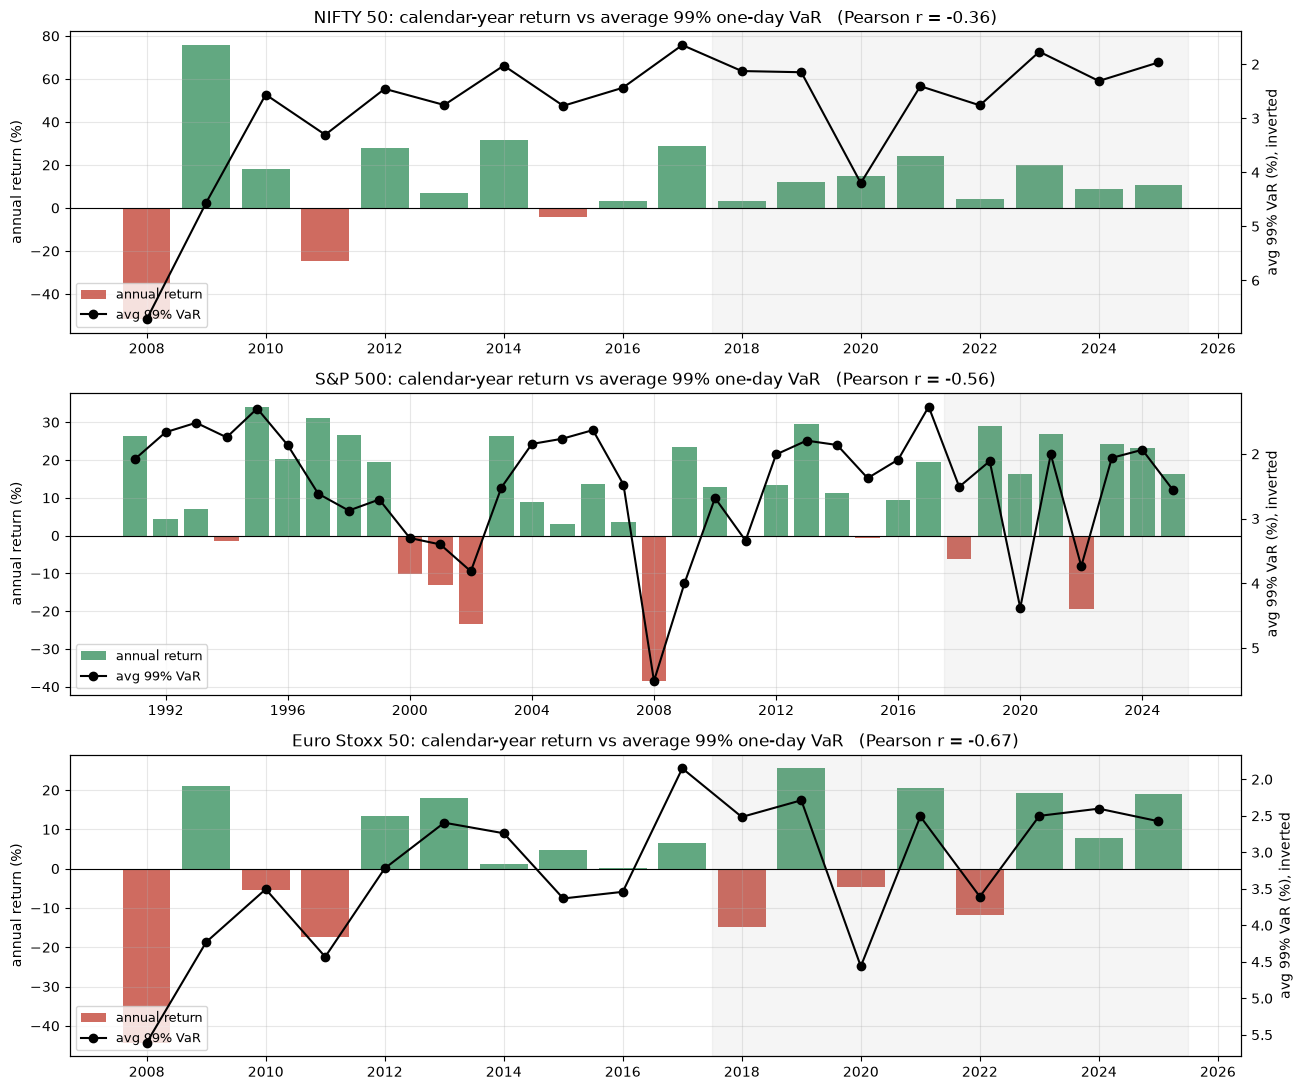

In [4]:
fig, axes = plt.subplots(len(INDICES), 1, figsize=(13, 11))
for ax, (name, t) in zip(axes, yearly.items()):
    colors = np.where(t["return"] >= 0, "#2e8b57", "#c0392b")
    ax.bar(t.index, t["return"], color=colors, alpha=0.75, label="annual return")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("annual return (%)")
    ax.axvspan(int(SPLIT[:4]) - 0.5, t.index[-1] + 0.5, color="0.5", alpha=0.08)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax2 = ax.twinx()
    ax2.plot(t.index, t["avg_VaR_99"], color="k", marker="o", lw=1.5, label="avg 99% VaR")
    ax2.invert_yaxis(); ax2.set_ylabel("avg 99% VaR (%), inverted"); ax2.grid(False)
    r = stats.pearsonr(t["return"], t["avg_VaR_99"])[0]
    ax.set_title(f"{name}: calendar-year return vs average 99% one-day VaR   (Pearson r = {r:+.2f})")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9)
plt.tight_layout()

## 3. Correlation tests

For each index, both risk measures are correlated with the annual return using

* **Pearson r**: linear correlation, sensitive to outlier years such as 2008 and 2020.
* **Spearman ρ**: rank correlation, which is robust to outliers.

Each is reported with its two-sided p-value. With only 8–35 years per index, p-values should be read with caution: a correlation needs to be around |r| > 0.7 to be significant with 8 years, and around |r| > 0.33 with 35.

Results are shown for all years and for the test window only.

In [5]:
def corr_row(x, y):
    pr, pp = stats.pearsonr(x, y)
    sr, sp = stats.spearmanr(x, y)
    return {"n": len(x), "Pearson r": pr, "Pearson p": pp, "Spearman ρ": sr, "Spearman p": sp}

rows = []
for name, t in yearly.items():
    for sample, sub in [("all years", t), ("test 2018–25", t[t["sample"] == "test"])]:
        for measure, label in [("avg_VaR_99", "average VaR (same year)"),
                               ("start_VaR_99", "start-of-year VaR (predictive)")]:
            rows.append({"index": name, "sample": sample, "VaR measure": label,
                         **corr_row(sub[measure], sub["return"])})

pooled = pd.concat(yearly.values())
for sample, sub in [("all years", pooled), ("test 2018–25", pooled[pooled["sample"] == "test"])]:
    for measure, label in [("avg_VaR_99", "average VaR (same year)"),
                           ("start_VaR_99", "start-of-year VaR (predictive)")]:
        rows.append({"index": "Pooled (all 3)", "sample": sample, "VaR measure": label,
                     **corr_row(sub[measure], sub["return"])})

corr = pd.DataFrame(rows).set_index(["VaR measure", "index", "sample"]).sort_index()
corr.style.format({"n": "{:.0f}", "Pearson r": "{:+.2f}", "Spearman ρ": "{:+.2f}",
                   "Pearson p": "{:.3f}", "Spearman p": "{:.3f}"}) \
    .map(lambda v: "color: #c0392b; font-weight: bold" if isinstance(v, float) and v < 0.05 else "",
         subset=["Pearson p", "Spearman p"])

### Scatter plots

Each point is one year, labelled with the year. Hollow markers are in-sample (training) years and filled markers are test years. The line is an ordinary least-squares fit through all years.

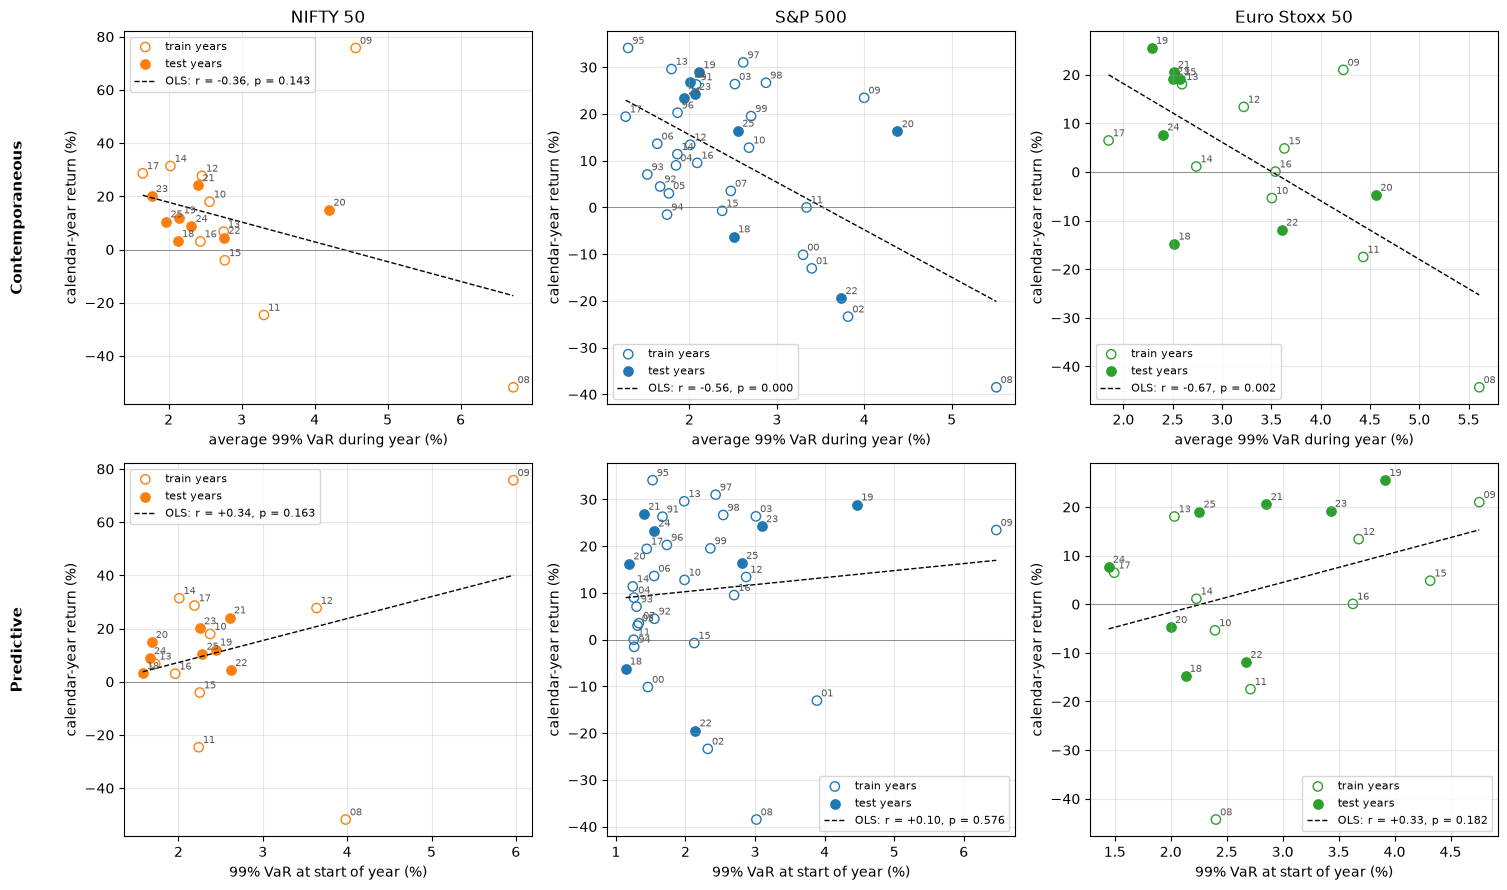

In [6]:
fig, axes = plt.subplots(2, len(INDICES), figsize=(15, 9))
for j, (name, t) in enumerate(yearly.items()):
    for i, (measure, label) in enumerate([("avg_VaR_99", "average 99% VaR during year (%)"),
                                         ("start_VaR_99", "99% VaR at start of year (%)")]):
        ax = axes[i, j]
        tr, te = t[t["sample"] == "train"], t[t["sample"] == "test"]
        ax.scatter(tr[measure], tr["return"], facecolors="none", edgecolors=COLORS[name], s=45, label="train years")
        ax.scatter(te[measure], te["return"], color=COLORS[name], s=45, label="test years")
        for yr, row in t.iterrows():
            ax.annotate(str(yr)[2:], (row[measure], row["return"]), fontsize=7,
                        xytext=(3, 3), textcoords="offset points", color="0.35")
        slope, intercept, r, p, _ = stats.linregress(t[measure], t["return"])
        xs = np.linspace(t[measure].min(), t[measure].max(), 50)
        ax.plot(xs, intercept + slope * xs, color="k", lw=1, ls="--",
                label=f"OLS: r = {r:+.2f}, p = {p:.3f}")
        ax.axhline(0, color="0.5", lw=0.6)
        ax.set_xlabel(label); ax.set_ylabel("calendar-year return (%)")
        ax.set_title(name if i == 0 else "")
        ax.legend(fontsize=8, loc="best")
axes[0, 0].annotate("Contemporaneous", xy=(-0.28, 0.5), xycoords="axes fraction",
                    rotation=90, va="center", fontsize=11, weight="bold")
axes[1, 0].annotate("Predictive", xy=(-0.28, 0.5), xycoords="axes fraction",
                    rotation=90, va="center", fontsize=11, weight="bold")
plt.tight_layout()

## 4. Rolling 252-day returns vs VaR

A daily view: the trailing one-year (252 trading days) return on each day against that day's 99% VaR.

* **Same-day:** VaR on day $t$ against the return over the 252 days ending on day $t$.
* **Forward:** VaR on day $t$ against the return over the *next* 252 days.

Consecutive observations overlap by 251 days, so ordinary p-values would be far too optimistic. Only the correlation coefficients are reported here. For significance, use the non-overlapping yearly tests above.

,same-day r (all),forward r (all),same-day r (test),forward r (test)
NIFTY 50,-0.464,0.291,-0.320,0.513
S&P 500,-0.506,0.108,-0.459,0.427
Euro Stoxx 50,-0.546,0.269,-0.402,0.502


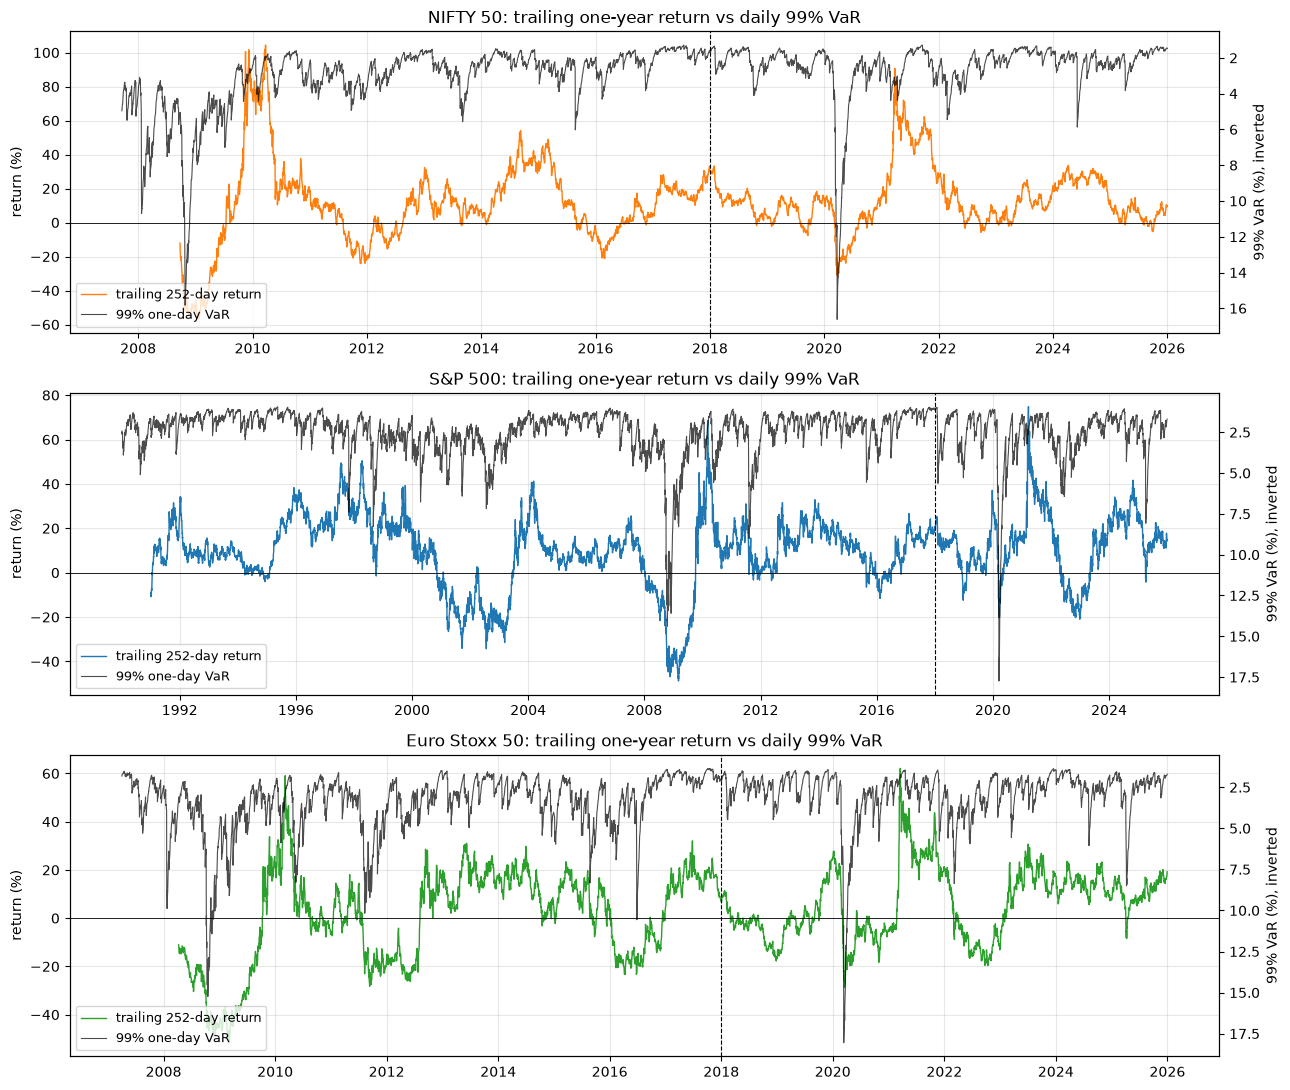

In [7]:
roll_rows = {}
fig, axes = plt.subplots(len(INDICES), 1, figsize=(13, 11), sharex=False)
for ax, (name, d) in zip(axes, daily.items()):
    p = prices[name].reindex(d.index)
    trailing = 100 * (p / p.shift(252) - 1)
    forward = 100 * (p.shift(-252) / p - 1)
    df = pd.DataFrame({"VaR": d["VaR_99"], "trailing": trailing, "forward": forward})
    roll_rows[name] = {
        "same-day r (all)":  df[["VaR", "trailing"]].dropna().corr().iloc[0, 1],
        "forward r (all)":   df[["VaR", "forward"]].dropna().corr().iloc[0, 1],
        "same-day r (test)": df.loc[SPLIT:, ["VaR", "trailing"]].dropna().corr().iloc[0, 1],
        "forward r (test)":  df.loc[SPLIT:, ["VaR", "forward"]].dropna().corr().iloc[0, 1],
    }
    ax.plot(df.index, df["trailing"], color=COLORS[name], lw=1, label="trailing 252-day return")
    ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("return (%)")
    ax.axvline(pd.Timestamp(SPLIT), color="k", ls="--", lw=0.8)
    ax2 = ax.twinx()
    ax2.plot(df.index, df["VaR"], color="k", lw=0.8, alpha=0.7, label="99% one-day VaR")
    ax2.invert_yaxis(); ax2.set_ylabel("99% VaR (%), inverted"); ax2.grid(False)
    ax.set_title(f"{name}: trailing one-year return vs daily 99% VaR")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9)
plt.tight_layout()

pd.DataFrame(roll_rows).T

## 5. Return per unit of risk by year

A simple risk-adjusted view: the annual return divided by the average 99% VaR during the year. It shows how many "1-in-100-day losses" each year's return was worth. Negative values mean the year lost money.

,NIFTY 50,S&P 500,Euro Stoxx 50
"mean annual return, test (%)",12.233,13.785,7.576
"mean avg 99% VaR, test (%)",2.461,2.662,2.870
"mean return / VaR, test",5.338,6.662,3.427
"mean annual return, all (%)",11.589,10.500,3.248
"mean avg 99% VaR, all (%)",2.829,2.496,3.240
"mean return / VaR, all",5.421,5.832,1.967


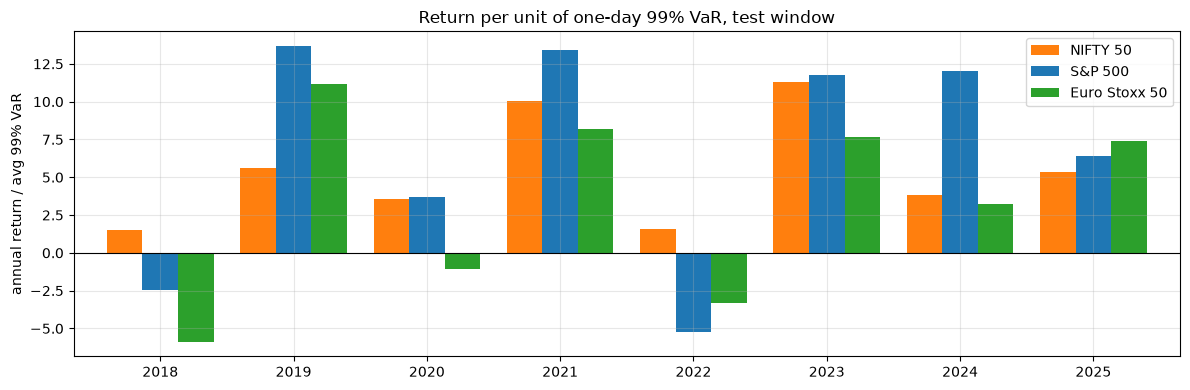

In [8]:
ratio = pd.DataFrame({name: t["return"] / t["avg_VaR_99"] for name, t in yearly.items()})
test_ratio = ratio.loc[int(SPLIT[:4]):]

ax = test_ratio.plot(kind="bar", color=[COLORS[n] for n in ratio.columns], width=0.8, figsize=(12, 4))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("annual return / avg 99% VaR"); ax.set_xlabel("")
ax.set_title("Return per unit of one-day 99% VaR, test window")
plt.xticks(rotation=0); plt.tight_layout()

summary = pd.DataFrame({
    name: {
        "mean annual return, test (%)": t.loc[t["sample"] == "test", "return"].mean(),
        "mean avg 99% VaR, test (%)": t.loc[t["sample"] == "test", "avg_VaR_99"].mean(),
        "mean return / VaR, test": test_ratio[name].mean(),
        "mean annual return, all (%)": t["return"].mean(),
        "mean avg 99% VaR, all (%)": t["avg_VaR_99"].mean(),
        "mean return / VaR, all": ratio[name].mean(),
    } for name, t in yearly.items()
})
summary

## 6. Findings

The cell below prints the key correlations. The discussion after it interprets them.

In [9]:
key = corr.reset_index()
key = key[key["index"] != "Pooled (all 3)"]
for (measure, sample), g in key.groupby(["VaR measure", "sample"], sort=False):
    print(f"\n{measure} — {sample}")
    for _, row in g.iterrows():
        flag = "significant" if row["Spearman p"] < 0.05 else "not significant"
        print(f"  {row['index']:14s} n={row['n']:>2.0f}  Pearson r={row['Pearson r']:+.2f}  "
              f"Spearman ρ={row['Spearman ρ']:+.2f} (p={row['Spearman p']:.3f}, {flag})")


average VaR (same year) — all years
  Euro Stoxx 50  n=18  Pearson r=-0.67  Spearman ρ=-0.56 (p=0.017, significant)
  NIFTY 50       n=18  Pearson r=-0.36  Spearman ρ=-0.38 (p=0.123, not significant)
  S&P 500        n=35  Pearson r=-0.56  Spearman ρ=-0.28 (p=0.107, not significant)

average VaR (same year) — test 2018–25
  Euro Stoxx 50  n= 8  Pearson r=-0.56  Spearman ρ=-0.64 (p=0.086, not significant)
  NIFTY 50       n= 8  Pearson r=+0.02  Spearman ρ=+0.02 (p=0.955, not significant)
  S&P 500        n= 8  Pearson r=-0.53  Spearman ρ=-0.67 (p=0.071, not significant)

start-of-year VaR (predictive) — all years
  Euro Stoxx 50  n=18  Pearson r=+0.33  Spearman ρ=+0.33 (p=0.179, not significant)
  NIFTY 50       n=18  Pearson r=+0.34  Spearman ρ=+0.22 (p=0.390, not significant)
  S&P 500        n=35  Pearson r=+0.10  Spearman ρ=+0.23 (p=0.188, not significant)

start-of-year VaR (predictive) — test 2018–25
  Euro Stoxx 50  n= 8  Pearson r=+0.54  Spearman ρ=+0.69 (p=0.058, not significa

### Interpretation

**1. Same-year VaR and returns are negatively correlated.** Years with high average VaR tend to be bad years.
* The relationship is strongest for the **Euro Stoxx 50** (Pearson r = −0.67, Spearman ρ = −0.56, both significant).
* Pooling all three indices gives r = −0.52 over all years and −0.45 over the test window, both significant.
* For the **S&P 500**, the Pearson correlation is significant (r = −0.56) but the rank correlation is not (ρ = −0.28). The linear result is driven by a few crash years (2002, 2008, 2022) rather than a steady relationship.
* The **NIFTY 50** shows only a weak negative link, and none at all in the test window (r = +0.02). Its highest-VaR test year, 2020, still ended up 14.9% because of the sharp recovery after the crash.

This is the leverage effect at an annual scale: falling prices raise volatility, so high risk and low returns occur together. It describes risk and return in the *same* year, so it cannot be used to forecast returns.

**2. Start-of-year VaR is positively, but not significantly, related to the following year's return.** Every index has a positive coefficient (r = +0.10 to +0.54), but none is significant at 5%. The pooled test-window correlation is the closest (ρ = +0.39, p = 0.06). The clearest examples are years that began just after a crash, such as 2009 and 2019: VaR was high on 1 January, and the following year's return was large. This is consistent with a risk premium or with mean reversion after sell-offs. However, with 8–35 yearly observations per index the evidence is weak, and a single year such as 2009 moves the result a lot.

**3. The daily rolling view tells the same story.** Over the test window, VaR has a correlation of −0.32 to −0.46 with the *trailing* one-year return and +0.43 to +0.51 with the *forward* one-year return. These figures come from heavily overlapping windows, so they are not independent evidence.

**4. Higher VaR was not rewarded across markets.** Over 2018–2025 the Euro Stoxx 50 carried the highest average 99% VaR (2.87%) but earned the lowest average annual return (7.6%). The S&P 500 earned the most per unit of VaR (6.7), ahead of the NIFTY 50 (5.3) and the Euro Stoxx 50 (3.4). For the portfolio stages, this means the minimum-VaR objective is unlikely to give up much return by reducing the Euro Stoxx weight.

**Caveats.** Returns exclude dividends. Years before 2018 use VaR from a model whose parameters were fitted on those same years. The yearly samples are small, so none of the predictive results should be treated as established.